# Earnings persistence

## What OneCredit uses this for

A OneCredit file that shows one profitable year can still be a weak counterparty. This notebook is the part of the company check that asks whether the latest year is a run-rate.

- Spearman rank of this year's net margin against last year's says whether profitability repeats.
- The revenue-growth distribution is the size of a normal year-to-year step, so a single jump can be read against that spread.
- Two neighbouring loss years is the early-warning flag a limit desk keeps, ahead of a one-year loss.
- Depreciation / assets is the non-cash charge on the asset base. The cash-flow extract has no operating-cash-flow line, so an accrual ratio is not part of this check.

A single profitable year is a weaker credit fact than a margin that repeats. This notebook stays on the industrial issuers in the listed panel and asks three things of the year-to-year path:

- Does this year's net margin rank with last year's?
- How large is a typical revenue step from one fiscal date to the next?
- How many issuers are loss-making in two neighbouring years?

`data/cash_flow.csv` carries the net-income starting line and depreciation. It does not carry cash from operations, so an accrual ratio (net income minus operating cash flow) cannot be formed from this extract. Depreciation / total assets is reported instead, as the non-cash charge sitting on the asset base.

Financials are excluded for the same reason as in the ratio notebook.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "credit_stats.py").exists():
    NOTEBOOK_DIR = Path.cwd() / "notebooks" / "credit_desk"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from credit_stats import (
    DATA_DIR,
    FIGURE_DIR,
    FINANCIAL_SECTOR_NAME,
    INSTITUTIONAL_INVESTOR_TYPES,
    LISTED_AMOUNT_UNIT,
    SSM_AMOUNT_UNIT,
    build_listed_panel,
    clean_state_name,
    age_in_years,
    cramers_v,
    distribution_row,
    epsilon_squared,
    herfindahl_from_positive_amounts,
    latest_rows,
    load_listed_statements,
    ownership_fraction,
    parse_ssm_financials,
    parse_ssm_profiles,
    peer_percentile,
    share_with_interval,
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


In [2]:
from scipy.stats import spearmanr

statements = load_listed_statements()
panel = build_listed_panel(statements)
operating_panel = panel.loc[~panel["is_financial_sector"]].copy()
operating_panel = operating_panel.sort_values(["registration_number", "fiscal_date"])

# shift(1) is the previous fiscal row for that issuer, after the sort above.
grouped = operating_panel.groupby("registration_number", sort=False)
operating_panel["prior_net_margin"] = grouped["net_profit_margin"].shift(1)
operating_panel["prior_revenue"] = grouped["revenue"].shift(1)
operating_panel["prior_loss"] = grouped["is_loss_making"].shift(1)
operating_panel["prior_fiscal_date"] = grouped["fiscal_date"].shift(1)
operating_panel["revenue_growth"] = operating_panel["revenue"] / operating_panel["prior_revenue"].where(
    operating_panel["prior_revenue"] > 0
) - 1
operating_panel["years_since_prior"] = (
    operating_panel["fiscal_date"] - operating_panel["prior_fiscal_date"]
).dt.days / 365.25

# A gap much longer than a year is a missing statement, not a run-rate.
adjacent = operating_panel.loc[operating_panel["years_since_prior"].between(0.7, 1.4)].copy()
latest_pair = latest_rows(adjacent, "registration_number", "fiscal_date")
print(f"Industrial issuer-years: {len(operating_panel):,}")
print(f"Adjacent year-pairs: {len(adjacent):,}")
print(f"Issuers with a latest adjacent pair: {len(latest_pair):,}")


Industrial issuer-years: 4,926
Adjacent year-pairs: 3,748
Issuers with a latest adjacent pair: 1,032


In [3]:
margin_pair = latest_pair[["net_profit_margin", "prior_net_margin"]].dropna()
margin_rho, margin_p = spearmanr(margin_pair["net_profit_margin"], margin_pair["prior_net_margin"])

growth = latest_pair["revenue_growth"].dropna()
growth_summary = distribution_row(growth, "revenue_growth")

consecutive_loss = share_with_interval(
    latest_pair["is_loss_making"] & latest_pair["prior_loss"].astype("boolean")
)
any_loss = share_with_interval(latest_pair["is_loss_making"])

# Stability: spread of the issuer's own net margins. Require three years so a
# two-point range is not treated as a volatility estimate.
margin_spread = (
    operating_panel.groupby("registration_number")["net_profit_margin"]
    .agg(year_count="count", margin_std="std")
    .reset_index()
)
margin_spread = margin_spread.loc[margin_spread["year_count"] >= 3]
spread_summary = distribution_row(margin_spread["margin_std"], "within_issuer_margin_std")

print(
    f"Spearman of latest net margin with the prior year: ρ = {margin_rho:.3f}, "
    f"p = {margin_p:.4g}, n = {len(margin_pair)}"
)
print(
    f"Median revenue growth on the latest adjacent pair: {growth.median():.1%} "
    f"(p25 {growth.quantile(0.25):.1%}, p75 {growth.quantile(0.75):.1%})"
)
print(
    f"Two neighbouring loss years: {consecutive_loss['share']:.1%} "
    f"(Wilson {consecutive_loss['wilson_low']:.1%}–{consecutive_loss['wilson_high']:.1%})"
)
print(
    f"Median within-issuer standard deviation of net margin, issuers with ≥ 3 years: "
    f"{spread_summary['median']:.3f} (n = {spread_summary['n']})"
)
pd.DataFrame([growth_summary, spread_summary])


Spearman of latest net margin with the prior year: ρ = 0.734, p = 1.501e-169, n = 1000
Median revenue growth on the latest adjacent pair: 4.4% (p25 -8.3%, p75 21.3%)
Two neighbouring loss years: 18.9% (Wilson 16.6%–21.4%)
Median within-issuer standard deviation of net margin, issuers with ≥ 3 years: 0.062 (n = 958)


,ratio,n,median,mean,p25,p75,iqr,skew,excess_kurtosis,mad_outlier_share
0,revenue_growth,1029,0.0441,0.1916,-0.0830,0.2128,0.2958,15.7949,288.3343,0.0787
1,within_issuer_margin_std,958,0.0617,0.3055,0.0293,0.1751,0.1458,15.0287,304.7644,0.1868


In [4]:
cash_flow = statements["cash_flow"][
    ["registration_number", "fiscal_date", "depreciation", "net_income_starting_line"]
].drop_duplicates(["registration_number", "fiscal_date"])
with_depreciation = latest_pair.merge(
    cash_flow, on=["registration_number", "fiscal_date"], how="left"
)
with_depreciation["depreciation_to_assets"] = with_depreciation["depreciation"] / with_depreciation[
    "total_assets"
].where(with_depreciation["total_assets"] > 0)

depreciation_summary = distribution_row(
    with_depreciation["depreciation_to_assets"], "depreciation_to_assets"
)
covered = with_depreciation["depreciation_to_assets"].notna().mean()
print(
    f"Latest adjacent pair with a depreciation line: {covered:.1%} of issuers. "
    f"Median depreciation/assets {depreciation_summary['median']:.3f}."
)
depreciation_summary


Latest adjacent pair with a depreciation line: 94.1% of issuers. Median depreciation/assets 0.020.


{'ratio': 'depreciation_to_assets',
 'n': 971,
 'median': 0.019539078156312624,
 'mean': 0.025602913763315194,
 'p25': 0.00898796697605423,
 'p75': 0.034404387721477275,
 'iqr': 0.025416420745423045,
 'skew': 2.208339166885563,
 'excess_kurtosis': 8.082820519275318,
 'mad_outlier_share': 0.03810504634397528}

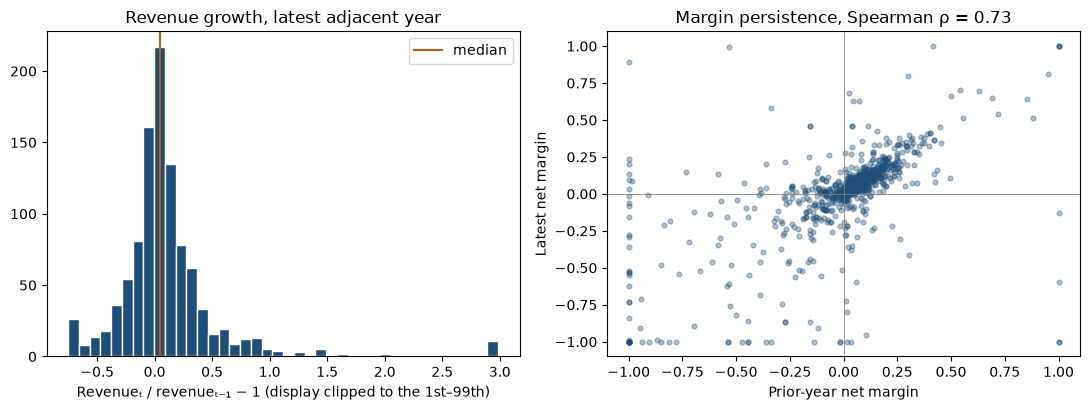

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
growth_plot = growth.clip(growth.quantile(0.01), growth.quantile(0.99))
axes[0].hist(growth_plot, bins=40, color="#1f4e79", edgecolor="white")
axes[0].axvline(growth.median(), color="#c45911", linewidth=1.5, label="median")
axes[0].set_title("Revenue growth, latest adjacent year")
axes[0].set_xlabel("Revenueₜ / revenueₜ₋₁ − 1 (display clipped to the 1st–99th)")
axes[0].legend()

axes[1].scatter(
    margin_pair["prior_net_margin"].clip(-1, 1),
    margin_pair["net_profit_margin"].clip(-1, 1),
    s=12,
    alpha=0.35,
    color="#1f4e79",
)
axes[1].axhline(0, color="grey", linewidth=0.6)
axes[1].axvline(0, color="grey", linewidth=0.6)
axes[1].set_xlabel("Prior-year net margin")
axes[1].set_ylabel("Latest net margin")
axes[1].set_title(f"Margin persistence, Spearman ρ = {margin_rho:.2f}")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "02_earnings_persistence.png", dpi=140)
plt.show()
